# Enriched Music Charts Analysis — 2026-W46


In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from scipy.stats import gaussian_kde
from IPython.display import display, Markdown, HTML
from matplotlib.ticker import FuncFormatter

# ==============================================================================
# GLOBAL VISUAL CONFIGURATION
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.titleweight"] = "normal"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 110

# Standardized color palette
YT_RED = "#FC4B4B"
YT_DARK_GREY = "#282828"
YT_TEXT = "#000000"
YT_GRAY = "#606060"
YT_GRID = "#E5E5E5"
YT_BG = "#FFFFFF"

# Style variables
BORDER_COLOR = "#A0A0A0"
BAR_HEIGHT = 0.65
GRID_STYLE = '--'
GRID_ALPHA = 0.7
TITLE_FONT_SIZE = 18

# Categorical palette for multi-series charts
CATEGORICAL_PALETTE = ['#FC4B4B', '#282828', '#4A90E2', '#F5A623', '#50E3C2']

# Format global to avoid scientific notation in DataFrames
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# ==============================================================================
# HELPER FUNCTIONS
# ==============================================================================
def format_number(x):
    if pd.isna(x): return "N/A"
    if x >= 1_000_000_000: return f"{x / 1_000_000_000:.1f}B"
    if x >= 1_000_000: return f"{x / 1_000_000:.1f}M"
    if x >= 1_000: return f"{x / 1_000:.1f}K"
    return f"{x:,.0f}"

def format_axis_millions(x, pos):
    if x >= 1_000_000: return f'{x/1_000_000:.0f}M'
    if x >= 1_000: return f'{x/1_000:.0f}K'
    return f'{x:.0f}'

def style_axes(ax, grid_axis='y'):
    for spine in ax.spines.values():
        spine.set_color(BORDER_COLOR)
        spine.set_linewidth(0.8)
    ax.tick_params(colors=YT_TEXT, labelsize=11)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.xaxis.grid(False)
    else:
        ax.xaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.yaxis.grid(False)

def add_bar_labels(ax, fmt="{:.0f}", suffix="", horizontal=True):
    if horizontal:
        for p in ax.patches:
            width = p.get_width()
            if width == 0: continue
            ax.text(width + (width * 0.02), p.get_y() + p.get_height() / 2,
                    f"{fmt.format(width)}{suffix}", ha='left', va='center', fontsize=11, color=YT_TEXT)
    else:
        for p in ax.patches:
            height = p.get_height()
            if height == 0: continue
            ax.text(p.get_x() + p.get_width() / 2, height + (height * 0.02),
                    f"{fmt.format(height)}{suffix}", ha='center', va='bottom', fontsize=11, color=YT_TEXT)

def get_continent(country):
    continents = {
        'North America': ['United States', 'Mexico', 'Canada', 'Puerto Rico'],
        'South America': ['Brazil', 'Argentina', 'Colombia', 'Chile', 'Peru', 'Venezuela'],
        'Europe': ['United Kingdom', 'Sweden', 'Germany', 'France', 'Spain', 'Italy', 'Netherlands', 'Turkey'],
        'Asia': ['India', 'South Korea', 'Japan', 'China', 'Indonesia', 'Pakistan', 'Philippines', 'Thailand', 'Vietnam'],
        'Africa': ['Nigeria', 'South Africa', 'Kenya', 'Ghana'],
        'Oceania': ['Australia', 'New Zealand'],
        'Middle East': ['Israel', 'UAE', 'Saudi Arabia']
    }
    for continent, countries in continents.items():
        if country in countries: return continent
    return 'Other'

# ==============================================================================
# METRIC FUNCTIONS (Inline for self-containment)
# ==============================================================================
def general_stats(df):
    return {
        "total_songs": int(len(df)),
        "unique_countries": int(df["artist_country"].nunique()),
        "unique_genres": int(df["macro_genre"].nunique()),
        "total_views": int(df["views"].sum()),
        "total_likes": int(df["likes"].sum()),
        "total_comments": int(df["comment_count"].sum()),
        "avg_views": float(df["views"].mean()),
        "avg_likes": float(df["likes"].mean()),
        "avg_engagement": float(df["engagement"].mean()),
    }

def top_countries(df, n=10):
    return (
        df.groupby("artist_country")
        .agg(total_songs=("rank", "count"), total_views=("views", "sum"))
        .reset_index()
        .sort_values("total_songs", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_countries_by_likes(df, n=10):
    return (
        df.groupby("artist_country")["likes"]
        .sum()
        .reset_index()
        .rename(columns={"likes": "total_likes"})
        .sort_values("total_likes", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_songs_by_country(df, country, metric="views", n=5):
    cols = ["track_name", "artist_names", "views", "likes", "engagement"]
    return (
        df[df["artist_country"] == country]
        .nlargest(n, metric)[cols]
        .reset_index(drop=True)
    )

def genre_stats(df):
    out = (
        df.groupby("macro_genre")
        .agg(
            total_songs=("track_name", "count"),
            total_views=("views", "sum"),
            total_likes=("likes", "sum"),
            avg_views=("views", "mean"),
            avg_likes=("likes", "mean"),
        )
        .reset_index()
    )
    out["engagement_rate"] = (
        out["total_likes"] / out["total_views"].replace(0, pd.NA) * 100
    ).fillna(0).round(2)
    return out.sort_values("total_songs", ascending=False).reset_index(drop=True)

def video_metrics(df):
    flags = {
        "Official": "is_official_video",
        "Lyric": "is_lyric_video",
        "Live": "is_live_performance",
    }
    rows = []
    total = len(df)
    for label, flag in flags.items():
        subset = df[df[flag] == 1]
        rows.append({
            "video_type": label,
            "count": int(len(subset)),
            "pct": float(len(subset) / total * 100) if total else 0.0,
            "avg_views": float(subset["views"].mean()) if len(subset) else 0.0,
            "avg_engagement": float(subset["engagement"].mean()) if len(subset) else 0.0,
        })
    return pd.DataFrame(rows)

def top_songs(df, metric="views", n=10):
    cols = ["rank", "track_name", "artist_names", metric, "artist_country"]
    return df.nlargest(n, metric)[cols].reset_index(drop=True)

def collaborations(df):
    grouped = (
        df.groupby("is_collaboration")
        .agg(
            count=("track_name", "count"),
            avg_views=("views", "mean"),
            avg_engagement=("engagement", "mean"),
        )
        .reset_index()
    )
    grouped["is_collaboration"] = grouped["is_collaboration"].map(
        {0: "Solo", 1: "Collaboration"}
    )
    return grouped


# ==============================================================================
# DATA LOADING
# ==============================================================================
DB_PATH = Path("../../charts_archive/3_enrich-chart-data/youtube_charts_2026-W46_enriched.db")
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM enriched_songs", conn)
conn.close()

df["upload_date"] = pd.to_datetime(df["upload_date"], errors="coerce")
df["upload_quarter"] = df["upload_date"].dt.quarter
df["engagement"] = np.where(df["views"] > 0, (df["likes"] / df["views"] * 100).round(2), 0.0)
df["continent"] = df["artist_country"].apply(get_continent)


## 1. Introduction

**Week:** 2026-W46 | **Period:** 2026-11-09 → 2026-11-15 | **Days:** 7

## 2. General Statistics

In [2]:
stats = general_stats(df)
display(pd.DataFrame(list(stats.items()), columns=['Metric', 'Value']))

,Metric,Value
0,total_songs,100.000
1,unique_countries,26.000
2,unique_genres,17.000
3,total_views,"1,371,255,651.000"
4,total_likes,"253,823,430.000"
5,total_comments,"13,355,791.000"
6,avg_views,"13,712,556.510"
7,avg_likes,"2,538,234.300"
8,avg_engagement,22.314


## 3. Continent Analysis

,continent,total_songs,total_views,total_likes
0,Asia,44,631823604,83866876
2,North America,27,322535014,99818900
1,Europe,12,164454336,17461216
4,Other,11,147562414,42680324
5,South America,5,91900540,9652437
3,Oceania,1,12979743,343677


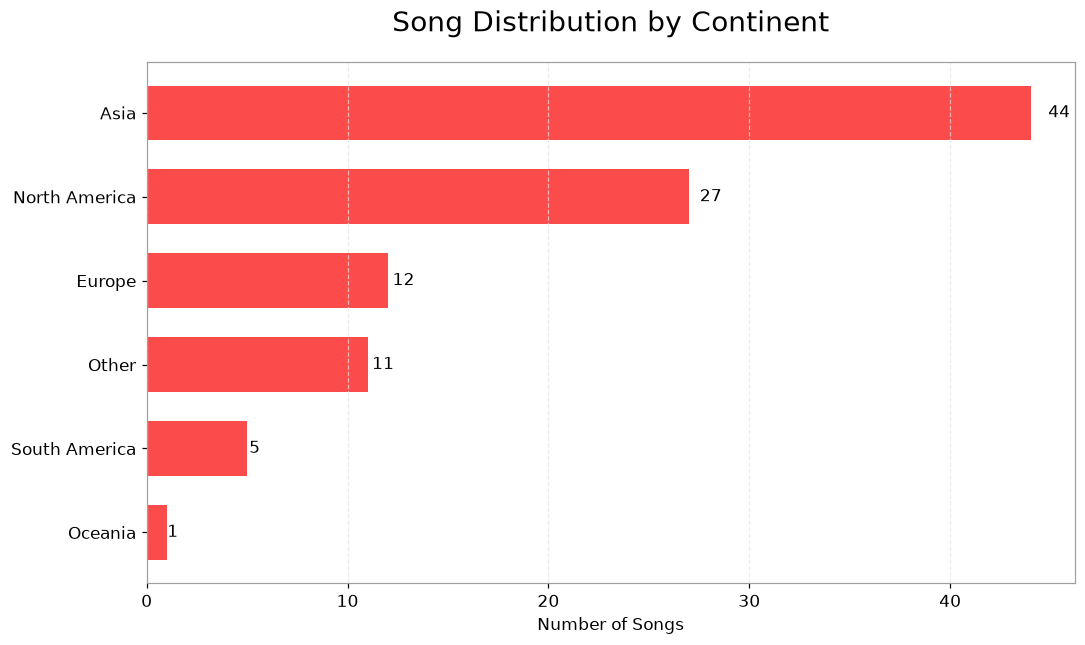

In [3]:
continent_stats = df.groupby('continent').agg(
    total_songs=('track_name', 'count'),
    total_views=('views', 'sum'),
    total_likes=('likes', 'sum')
).reset_index().sort_values('total_songs', ascending=False)

display(continent_stats)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

bars = ax.barh(continent_stats['continent'], continent_stats['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Song Distribution by Continent', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

ax.invert_yaxis() # Ensure the largest category is at the top

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

## 4. Country Analysis

### 4.1. Top Countries by Song Count

,artist_country,total_songs,total_views,percentage
5,India,31,457694845,38.270
23,United States,18,203085048,22.220
18,South Korea,7,98172618,8.640
22,United Kingdom,6,78605268,7.410
8,Mexico,4,36507577,4.940
1,Brazil,4,51238569,4.940
9,Multi-country,4,50144460,4.940
16,Puerto Rico,3,56568770,3.700
2,Canada,2,26373619,2.470
20,Thailand,2,17880673,2.470


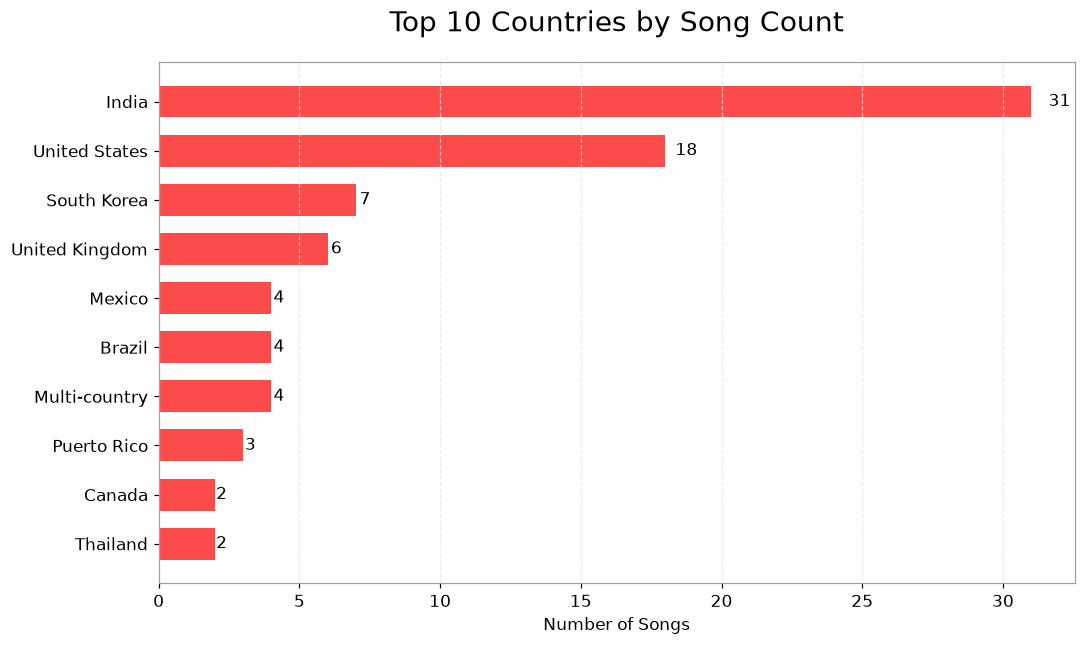

In [4]:
top_countries = (df
    .groupby('artist_country')
    .agg(total_songs=('rank', 'count'), total_views=('views', 'sum'))
    .reset_index()
    .sort_values('total_songs', ascending=False)
    .head(10))
total = top_countries['total_songs'].sum()
top_countries['percentage'] = (top_countries['total_songs'] / total * 100).round(2)
display(top_countries)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_countries['artist_country'], top_countries['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

### 4.2. Top Countries by Total Likes

,artist_country,total_likes_fmt
23,United States,82.5M
18,South Korea,38.9M
5,India,37.1M
13,Panama,21.0M
11,Norway,13.5M
4,France,12.2M
2,Canada,11.5M
3,Colombia,8.9M
20,Thailand,4.5M
16,Puerto Rico,4.1M


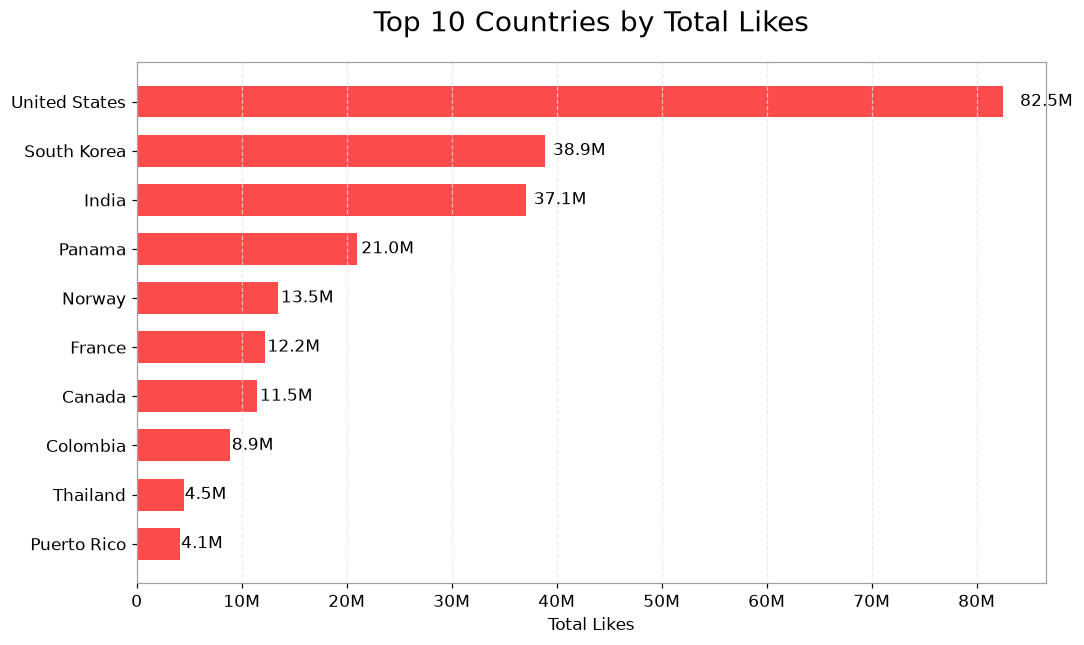

In [5]:
top_likes = (df
    .groupby('artist_country')['likes']
    .sum()
    .reset_index()
    .rename(columns={'likes': 'total_likes'})
    .sort_values('total_likes', ascending=False)
    .head(10))

def format_likes(x):
    if x >= 1_000_000: return f'{x/1_000_000:.1f}M'
    if x >= 1_000: return f'{x/1_000:.1f}K'
    return str(x)

top_likes['total_likes_fmt'] = top_likes['total_likes'].apply(format_likes)
display(top_likes[['artist_country', 'total_likes_fmt']])

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_likes['artist_country'], top_likes['total_likes'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Total Likes', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Total Likes', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + (width*0.02), p.get_y() + p.get_height()/2, 
                format_likes(width), ha='left', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

### 4.3. Top 5 Songs by Top 5 Countries

In [6]:
# Limit to top 5 countries
top_countries_list = df['artist_country'].value_counts().head(5).index.tolist()
for country in top_countries_list:
    display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))
    display(HTML(f'<h4 style="color: {YT_TEXT}; margin-bottom: 10px;">{country}</h4>'))
    
    df_country = df[df['artist_country'] == country]
    
    # Top 5 by views
    top_views = df_country.nlargest(5, 'views')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_views['views'] = top_views['views'].apply(format_number)
    top_views['likes'] = top_views['likes'].apply(format_number)
    display(HTML('<b>Top 5 by views:</b>'))
    display(top_views)
    
    # Top 5 by likes
    top_likes_country = df_country.nlargest(5, 'likes')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_likes_country['views'] = top_likes_country['views'].apply(format_number)
    top_likes_country['likes'] = top_likes_country['likes'].apply(format_number)
    display(HTML('<b>Top 5 by likes:</b>'))
    display(top_likes_country)

display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))

,track_name,artist_names,views,likes,engagement
1,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37.8M,715.8K,1.890
3,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,36.0M,2.2M,6.200
6,गुज़ारिश,Satinder Sartaaj,28.3M,645.3K,2.280
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.090
10,Barsaat,Banjaare & Roni,23.2M,1.3M,5.790


,track_name,artist_names,views,likes,engagement
76,Udaarian,Satinder Sartaaj,9.2M,4.5M,49.000
97,Hookah Bar,Himesh Reshammiya & Vineet Kumar Singh & Aaman...,7.9M,4.1M,52.160
20,Shararat,Shashwat Sachdev & Madhubanti Bagchi & Jasmine...,16.0M,3.1M,19.470
46,Bairan,Banjaare,11.6M,2.6M,22.680
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.090


,track_name,artist_names,views,likes,engagement
14,NEON,A2O & A2O LITE,18.6M,655.8K,3.530
21,Thriller,Michael Jackson,16.0M,2.9M,18.080
26,The One That Got Away,Katy Perry,14.8M,5.4M,36.630
33,Hootie Frutti,KATSEYE,13.3M,1.4M,10.170
35,Stop The Wedding!,Ashe,13.1M,248.1K,1.900


,track_name,artist_names,views,likes,engagement
94,Love The Way You Lie (feat. Rihanna),Eminem,8.0M,15.4M,191.140
60,Bring Me To Life,Evanescence,10.1M,12.1M,119.520
84,Poker Face,Lady Gaga,8.4M,9.0M,107.100
66,November Rain,Guns N' Roses,9.6M,8.8M,91.660
40,Just Give Me a Reason (feat. Nate Ruess),P!nk,12.6M,7.9M,62.770


,track_name,artist_names,views,likes,engagement
8,체포하겠어,ILLIT,23.7M,623.2K,2.630
12,ADDICTED,JISOO,22.3M,1.2M,5.530
34,It's Me,ILLIT,13.2M,1.7M,12.540
50,Gangnam Style (강남스타일),Psy,11.3M,32.4M,287.590
52,BAD,ATEEZ,10.9M,1.5M,13.300


,track_name,artist_names,views,likes,engagement
50,Gangnam Style (강남스타일),Psy,11.3M,32.4M,287.590
34,It's Me,ILLIT,13.2M,1.7M,12.540
52,BAD,ATEEZ,10.9M,1.5M,13.300
12,ADDICTED,JISOO,22.3M,1.2M,5.530
85,DESERVE,BABYMONSTER,8.4M,890.2K,10.570


,track_name,artist_names,views,likes,engagement
16,Training Season,Dua Lipa,17.7M,952.8K,5.390
24,Sebebi Yar (Live),BLOK3,15.8M,591.7K,3.740
32,อย่ามากกว่าฉันก็พอ (Jealous),GAVIND,13.9M,12.2K,0.090
49,Kayıp Kalp,BLOK3,11.3M,409.9K,3.640
59,TRALALA,manifest,10.2M,654.2K,6.400


,track_name,artist_names,views,likes,engagement
16,Training Season,Dua Lipa,17.7M,952.8K,5.390
59,TRALALA,manifest,10.2M,654.2K,6.400
24,Sebebi Yar (Live),BLOK3,15.8M,591.7K,3.740
64,Kırgınım,BLOK3,9.8M,416.5K,4.260
49,Kayıp Kalp,BLOK3,11.3M,409.9K,3.640


,track_name,artist_names,views,likes,engagement
19,Pós (Ao Vivo),Felipe e Rodrigo,17.0M,207.5K,1.220
23,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,15.9M,117.5K,0.740
57,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,10.3M,185.6K,1.800
95,Bonito Bonito,Thiago Navarro Music,8.0M,263.4K,3.290


,track_name,artist_names,views,likes,engagement
95,Bonito Bonito,Thiago Navarro Music,8.0M,263.4K,3.290
19,Pós (Ao Vivo),Felipe e Rodrigo,17.0M,207.5K,1.220
57,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,10.3M,185.6K,1.800
23,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,15.9M,117.5K,0.740


## 5. Genre Analysis

In [7]:
genre_stats = (df
    .groupby('macro_genre')
    .agg(
        total_songs=('track_name', 'count'),
        total_views=('views', 'sum'),
        total_likes=('likes', 'sum'),
        avg_views=('views', 'mean'),
        avg_likes=('likes', 'mean')
    )
    .reset_index()
    .sort_values('total_songs', ascending=False))

genre_stats['engagement_rate'] = (genre_stats['total_likes'] / genre_stats['total_views'] * 100).round(2).fillna(0)
display(genre_stats.head(10)[['macro_genre', 'total_songs', 'engagement_rate']])

,macro_genre,total_songs,engagement_rate
4,Indian Pop,30,7.990
12,Pop,21,25.830
3,Hip-Hop/Rap,8,18.260
7,K-Pop/K-Rock,7,39.580
14,Regional Mexicano,6,9.530
2,Electrónica/Dance,5,26.070
13,Reggaetón/Trap Latino,5,32.610
9,Multi-genre,4,6.580
1,Brazilian Regional,3,1.180
6,J-Pop/J-Rock,2,25.050


### 5.2. Genre Distribution Treemap

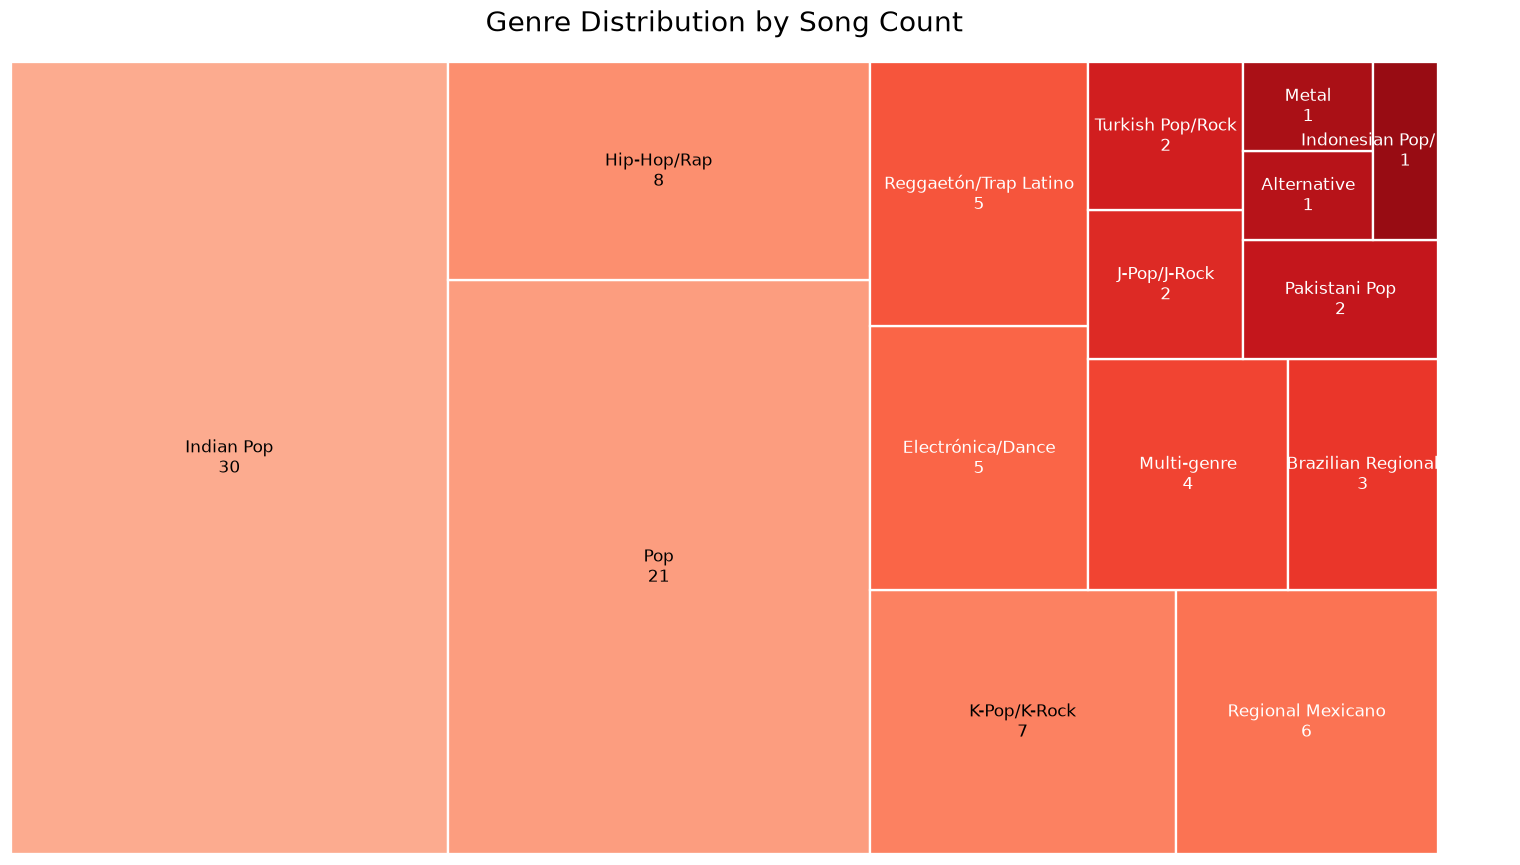

In [8]:
treemap_data = genre_stats.head(15).copy()
sizes = treemap_data['total_songs'].values
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(sizes)))

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_facecolor(YT_BG); fig.patch.set_facecolor(YT_BG)

# Calculate rectangles
rects = squarify.normalize_sizes(sizes, 14, 8)
rects = squarify.squarify(rects, 0, 0, 14, 8)

for i, (rect, color) in enumerate(zip(rects, colors)):
    # Determine luminance to decide text color (white on dark, black on light)
    luminance = 0.299*color[0] + 0.587*color[1] + 0.114*color[2]
    text_color = 'white' if luminance < 0.6 else 'black'
    
    rect_obj = plt.Rectangle(
        (rect['x'], rect['y']), rect['dx'], rect['dy'], 
        facecolor=color, edgecolor='white', linewidth=1.5
    )
    ax.add_patch(rect_obj)
    
    label = f"{treemap_data['macro_genre'].iloc[i]}\n{format_number(treemap_data['total_songs'].iloc[i])}"
    ax.text(
        rect['x'] + rect['dx']/2, rect['y'] + rect['dy']/2, label, 
        ha='center', va='center', fontsize=11, color=text_color
    )

ax.set_xlim(0, 14); ax.set_ylim(0, 8)
ax.set_title('Genre Distribution by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.axis('off')
plt.tight_layout(); plt.show()

### 5.3. Engagement Rate by Genre

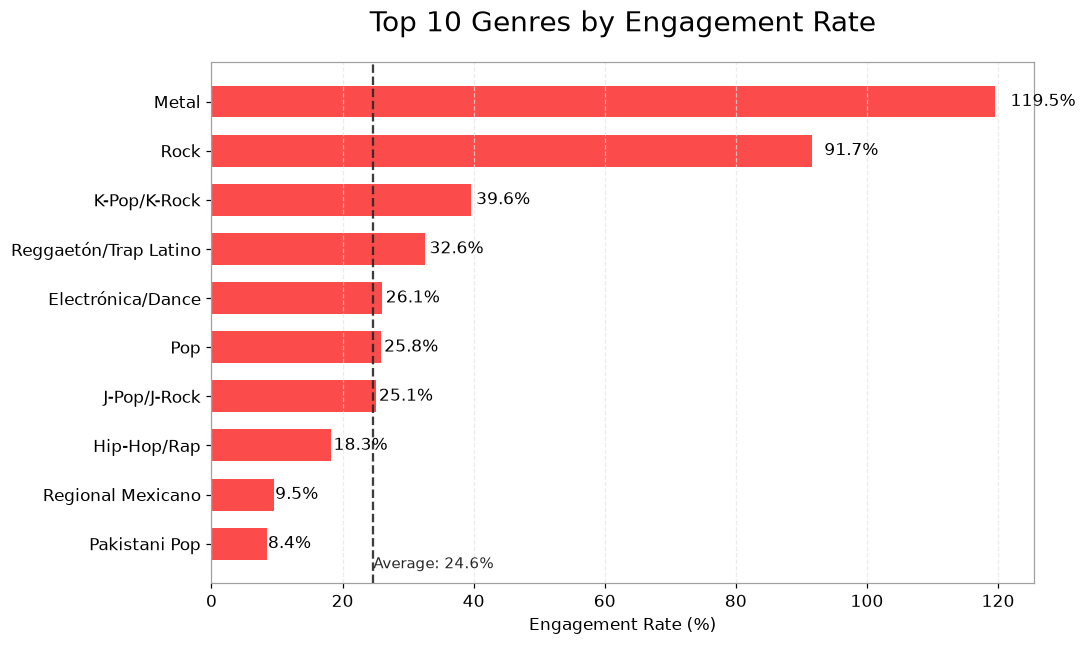

,Statistic,Value,Genre
0,Average,24.592,
1,Median,9.530,
2,Max,119.520,Metal
3,Min,0.470,OPM


In [9]:
engagement_chart = genre_stats.sort_values('engagement_rate', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(engagement_chart['macro_genre'], engagement_chart['engagement_rate'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Engagement Rate (%)', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Genres by Engagement Rate', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.1f}', suffix='%', horizontal=True)

avg_engagement = genre_stats['engagement_rate'].mean()
ax.axvline(x=avg_engagement, color=YT_DARK_GREY, linestyle='--', linewidth=1.5, alpha=0.9)
ax.text(avg_engagement + 0.1, len(engagement_chart) - 0.5, f'Average: {avg_engagement:.1f}%',
        fontsize=10, color=YT_DARK_GREY)

plt.tight_layout(); plt.show()

# Summary table
stats_summary = pd.DataFrame({
    'Statistic': ['Average', 'Median', 'Max', 'Min'],
    'Value': [avg_engagement, genre_stats['engagement_rate'].median(), genre_stats['engagement_rate'].max(), genre_stats['engagement_rate'].min()],
    'Genre': ['', '', genre_stats.loc[genre_stats['engagement_rate'].idxmax(), 'macro_genre'], genre_stats.loc[genre_stats['engagement_rate'].idxmin(), 'macro_genre']]
})
display(stats_summary)

### 5.4. Country-Genre Distribution Heatmap

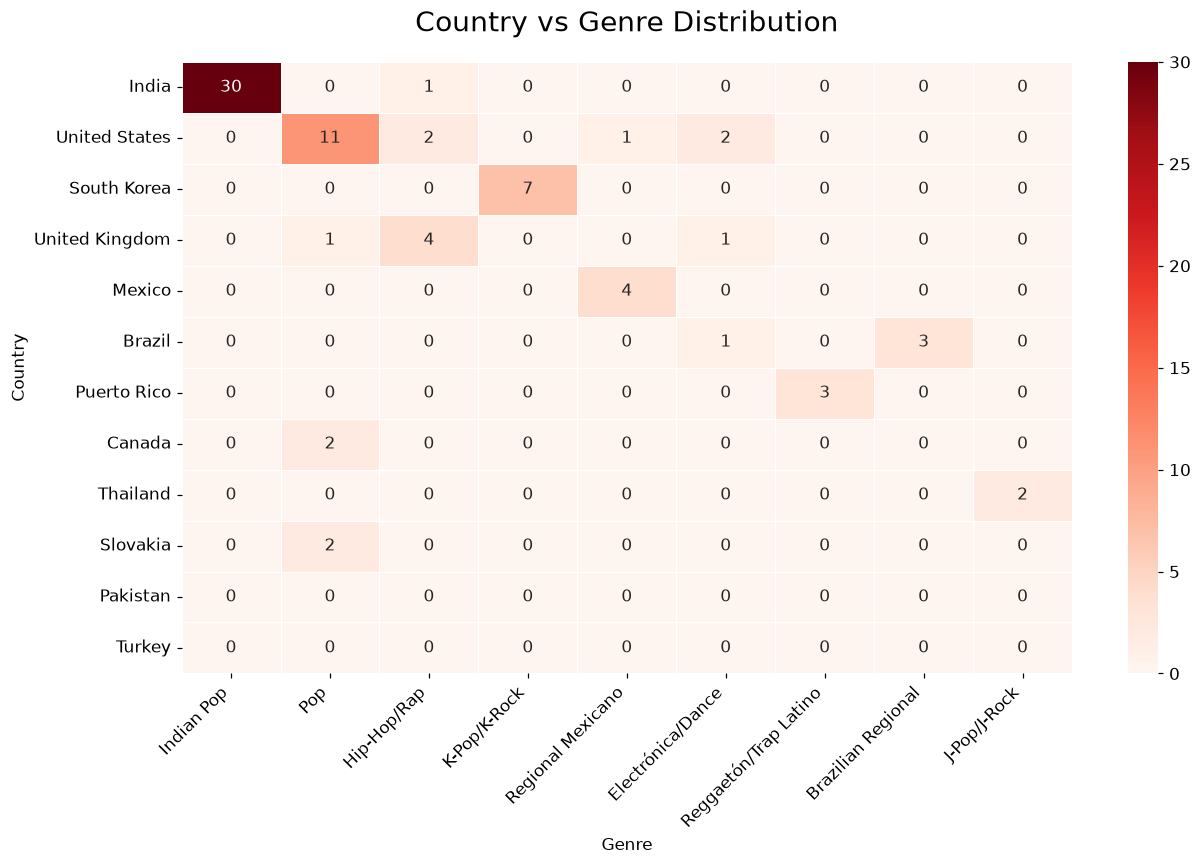

In [10]:
df_analysis = df[~df['artist_country'].isin(['Multi-country', 'Unknown'])]
if not df_analysis.empty:
    matrix = pd.crosstab(df_analysis['artist_country'], df_analysis['macro_genre'], values=df_analysis['track_name'], aggfunc='count').fillna(0)
    top_countries_h = matrix.sum(axis=1).sort_values(ascending=False).head(12).index
    top_genres = [g for g in genre_stats.nlargest(10, 'total_songs')['macro_genre'].tolist() if g in matrix.columns]
    
    if len(top_countries_h) > 0 and len(top_genres) > 0:
        matrix_heatmap = matrix.loc[top_countries_h, top_genres].astype(int)
        
        fig, ax = plt.subplots(figsize=(12, 8))
        fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)
        
        sns.heatmap(
            matrix_heatmap, annot=True, fmt='d', cmap='Reds',
            xticklabels=True, yticklabels=True, linewidths=0.5, linecolor='white', ax=ax
        )
        
        ax.set_title('Country vs Genre Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
        ax.set_xlabel('Genre', fontsize=11, color=YT_TEXT)
        ax.set_ylabel('Country', fontsize=11, color=YT_TEXT)
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout(); plt.show()

## 6. Song Metrics

### 6.1. Top Songs by Views

In [11]:
display(df.nlargest(10, 'views')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'views', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,views,artist_country
0,1,Dai Dai,Shakira & Burna Boy,Pop,40661971,Colombia
1,2,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,Indian Pop,37827726,India
2,3,POKITO,Daddy Yankee & Diljit Dosanjh,Reggaetón/Trap Latino,36123561,Puerto Rico
3,4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,Indian Pop,35997065,India
4,5,BbY WOW,KAROL G & Judeline & rusowsky,Pop,30531284,Spain
5,6,Alfaaz,Hamza Malik & Zain Zohaib,Pakistani Pop,29896719,Pakistan
6,7,गुज़ारिश,Satinder Sartaaj,Indian Pop,28263770,India
7,8,Пешта,Xamdam Sobirov,Pop,24191686,Uzbekistan
8,9,체포하겠어,ILLIT,K-Pop/K-Rock,23694267,South Korea
9,10,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,Hip-Hop/Rap,23528049,India


### 6.2. Top Songs by Likes

In [12]:
display(df.nlargest(10, 'likes')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'likes', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,likes,artist_country
50,51,Gangnam Style (강남스타일),Psy,K-Pop/K-Rock,32383013,South Korea
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,Reggaetón/Trap Latino,20970220,Panama
94,95,Love The Way You Lie (feat. Rihanna),Eminem,Hip-Hop/Rap,15369558,United States
86,87,Runaway,AURORA,Pop,13460586,Norway
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,Electrónica/Dance,12199796,France
60,61,Bring Me To Life,Evanescence,Metal,12072437,United States
22,23,Save Your Tears,The Weeknd,Pop,11135845,Canada
84,85,Poker Face,Lady Gaga,Pop,9040147,United States
0,1,Dai Dai,Shakira & Burna Boy,Pop,8878463,Colombia
66,67,November Rain,Guns N' Roses,Rock,8803207,United States


### 6.3. Top Songs by Engagement

In [13]:
display(df.nlargest(10, 'engagement')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'engagement', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,engagement,artist_country
50,51,Gangnam Style (강남스타일),Psy,K-Pop/K-Rock,287.590,South Korea
94,95,Love The Way You Lie (feat. Rihanna),Eminem,Hip-Hop/Rap,191.140,United States
86,87,Runaway,AURORA,Pop,160.180,Norway
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,Reggaetón/Trap Latino,149.520,Panama
60,61,Bring Me To Life,Evanescence,Metal,119.520,United States
84,85,Poker Face,Lady Gaga,Pop,107.100,United States
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,Electrónica/Dance,96.580,France
66,67,November Rain,Guns N' Roses,Rock,91.660,United States
58,59,All I Want for Christmas Is You,Mariah Carey,Pop,72.350,United States
22,23,Save Your Tears,The Weeknd,Pop,69.710,Canada


## 7. Video Metrics

### 7.1. Video Summary

In [14]:
video_stats = {
    'Category': ['Official Videos', 'Lyric Videos', 'Live Performances', 'Collaborations'],
    'Count': [df['is_official_video'].sum(), df['is_lyric_video'].sum(), df['is_live_performance'].sum(), df['is_collaboration'].sum()]
}
v_stats_df = pd.DataFrame(video_stats)
v_stats_df['Percentage'] = (v_stats_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(v_stats_df)

,Category,Count,Percentage
0,Official Videos,75,75.0%
1,Lyric Videos,53,53.0%
2,Live Performances,56,56.0%
3,Collaborations,19,19.0%


### 7.2. Views by Video Type

,Video Type,Total Videos,Avg Views,Median Views,Std Dev
0,Live,4,"13,210,918","13,094,758","3,796,085"
1,Lyric,16,"12,270,200","10,439,221","5,602,262"
2,Official,75,"14,185,320","11,595,019","7,415,718"
3,Other,5,"11,637,952","8,368,004","7,046,705"


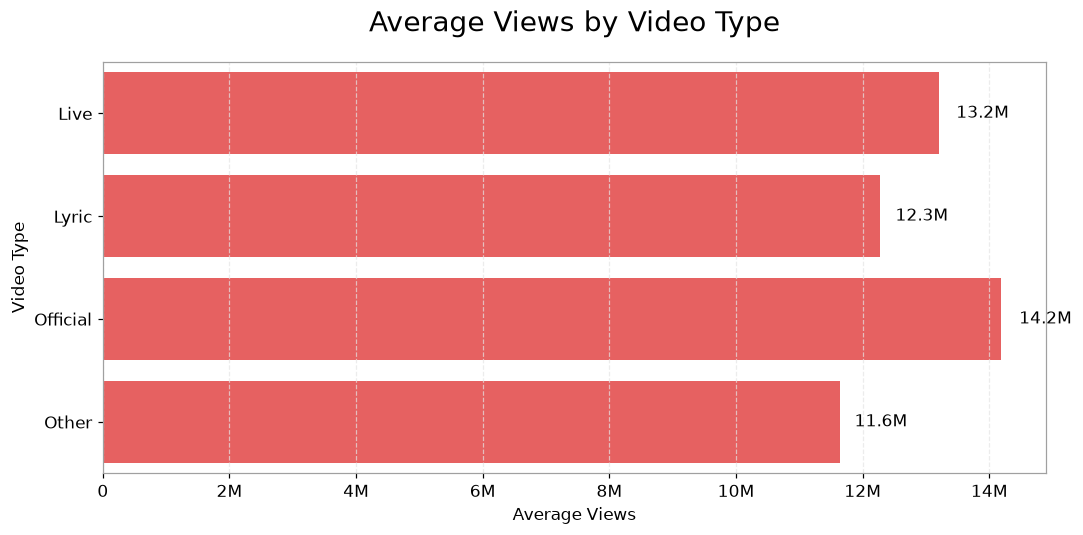

In [15]:
df_video = df.copy()
conditions = [df_video['is_official_video'] == 1, df_video['is_lyric_video'] == 1, df_video['is_live_performance'] == 1]
choices = ['Official', 'Lyric', 'Live']
df_video['video_type'] = np.select(conditions, choices, default='Other')

views_stats = df_video.groupby('video_type').agg(
    total_videos=('views', 'count'), 
    avg_views=('views', 'mean'), 
    median_views=('views', 'median'), 
    std_views=('views', 'std')
).round(2).reset_index()

table_views = views_stats.copy()
table_views['total_videos'] = table_views['total_videos'].astype(int)
table_views['avg_views'] = table_views['avg_views'].apply(lambda x: f'{x:,.0f}')
table_views['median_views'] = table_views['median_views'].apply(lambda x: f'{x:,.0f}')
table_views['std_views'] = table_views['std_views'].apply(lambda x: f'{x:,.0f}')
table_views.columns = ['Video Type', 'Total Videos', 'Avg Views', 'Median Views', 'Std Dev']
display(table_views)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

sns.barplot(data=views_stats, y='video_type', x='avg_views', ax=ax, color=YT_RED, errorbar=None)

ax.set_title('Average Views by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Average Views', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + (width*0.02), p.get_y() + p.get_height()/2, 
                f'{width/1_000_000:.1f}M', ha='left', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

### 7.3. Engagement by Video Type

,Video Type,Avg Engagement (%)
0,Live,3.252
1,Lyric,9.364
2,Official,24.761
3,Other,42.308


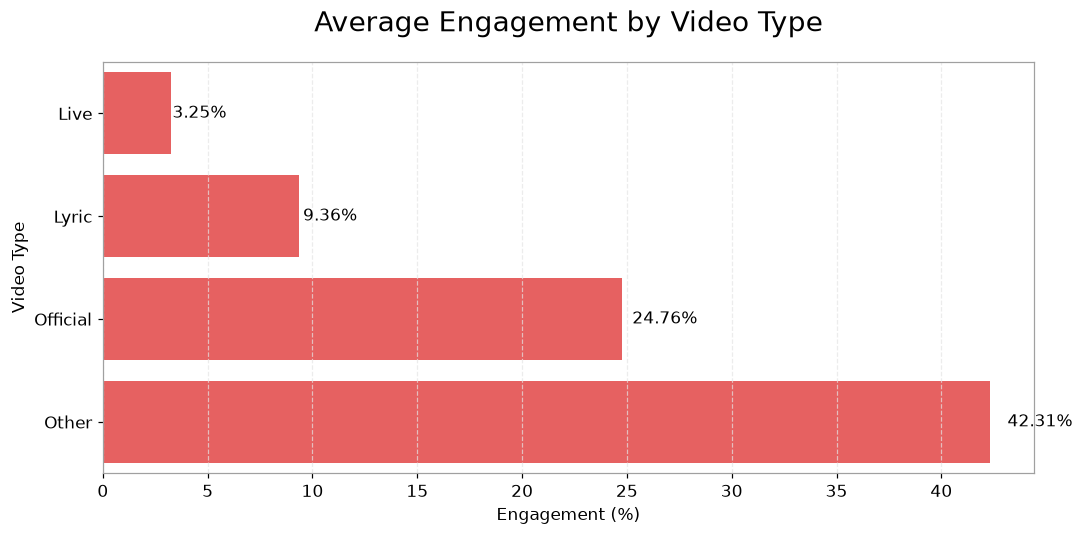

In [16]:
engagement_by_type = df_video.groupby('video_type')['engagement'].mean().reset_index()
engagement_by_type.columns = ['Video Type', 'Avg Engagement (%)']
display(engagement_by_type)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

sns.barplot(data=engagement_by_type, y='Video Type', x='Avg Engagement (%)', ax=ax, color=YT_RED, errorbar=None)

ax.set_title('Average Engagement by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Engagement (%)', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.2f}', suffix='%', horizontal=True)

plt.tight_layout(); plt.show()

### 7.4. Duration Analysis

,Statistic,Value
0,Average (min),3.7
1,Minimum (s),81
2,Maximum (s),557
3,Median (s),214.5
4,Q1 (min),3.0
5,Q3 (min),4.0


/tmp/ipykernel_2174/3490382924.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax2.boxplot(


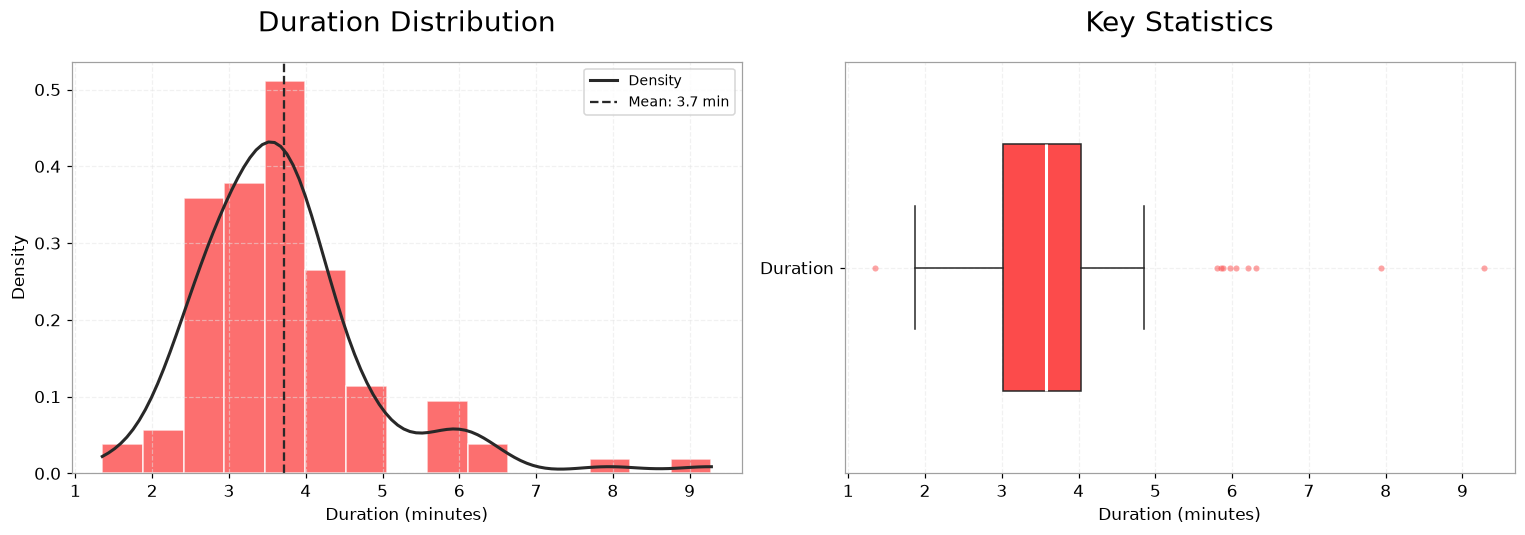

In [17]:
duration_minutes = df['duration_s'] / 60

dur_stats = pd.DataFrame({
    'Statistic': ['Average (min)', 'Minimum (s)', 'Maximum (s)', 'Median (s)', 'Q1 (min)', 'Q3 (min)'],
    'Value': [f'{duration_minutes.mean():.1f}', f'{df["duration_s"].min()}', f'{df["duration_s"].max()}', f'{df["duration_s"].median()}', f'{duration_minutes.quantile(0.25):.1f}', f'{duration_minutes.quantile(0.75):.1f}']
})
display(dur_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(YT_BG)

# Histogram
ax1 = axes[0]
ax1.set_facecolor(YT_BG)
n, bins, patches = ax1.hist(duration_minutes, bins=15, edgecolor='white', alpha=0.8, density=True, color=YT_RED)
kde = gaussian_kde(duration_minutes)
x = np.linspace(duration_minutes.min(), duration_minutes.max(), 100)
ax1.plot(x, kde(x), color=YT_DARK_GREY, linewidth=2, label='Density')
ax1.axvline(duration_minutes.mean(), color=YT_DARK_GREY, linestyle='--', linewidth=1.5, label=f'Mean: {duration_minutes.mean():.1f} min')
ax1.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Density', fontsize=11, color=YT_TEXT)
ax1.set_title('Duration Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.legend(loc='upper right', fontsize=9)

# Boxplot
ax2 = axes[1]
ax2.set_facecolor(YT_BG)
bp = ax2.boxplot(
    duration_minutes, vert=False, patch_artist=True, widths=0.6, 
    boxprops=dict(facecolor=YT_RED, color=YT_DARK_GREY), 
    whiskerprops=dict(color=YT_DARK_GREY), capprops=dict(color=YT_DARK_GREY), 
    medianprops=dict(color='white', linewidth=2), 
    flierprops=dict(marker='o', markerfacecolor=YT_RED, markersize=4, alpha=0.5, markeredgecolor='none')
)
ax2.set_yticks([1]); ax2.set_yticklabels(['Duration'], fontsize=11, color=YT_TEXT)
ax2.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax2.set_title('Key Statistics', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

for ax in axes:
    style_axes(ax, grid_axis='x')
    ax.grid(True, color=YT_GRID, linestyle='--', alpha=0.5)

plt.tight_layout(); plt.show()

### 7.5. Channel Type Distribution

,Channel Type,Count,Percentage
0,General,51,51.0%
1,Label/Studio,28,28.0%
2,VEVO,18,18.0%
3,User Channel,1,1.0%
4,Artist Channel,1,1.0%
5,Topic,1,1.0%


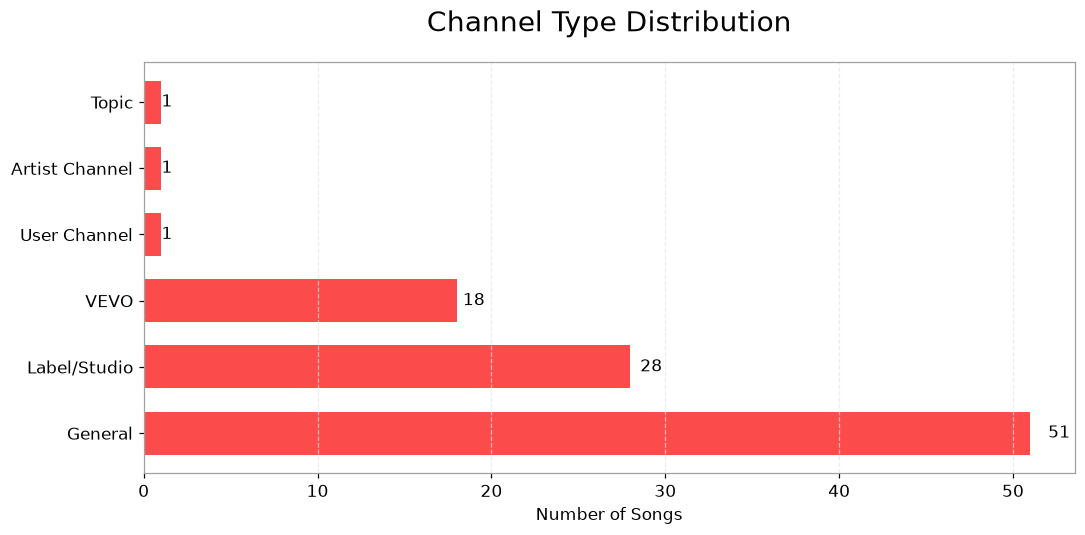

In [18]:
channel_counts = df['channel_type'].value_counts()
ch_df = pd.DataFrame({'Channel Type': channel_counts.index, 'Count': channel_counts.values})
ch_df['Percentage'] = (ch_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(ch_df)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(channel_counts.index, channel_counts.values, color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Channel Type Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

## 8. Temporal Analysis

In [19]:
top5_genres = genre_stats.nlargest(5, 'total_songs')['macro_genre'].tolist()
df_temporal = df[df['macro_genre'].isin(top5_genres)].copy()

temporal_views = df_temporal.groupby(['upload_quarter', 'macro_genre'])['views'].sum().reset_index()
temporal_engagement = df_temporal.groupby(['upload_quarter', 'macro_genre'])['engagement'].mean().reset_index()

### 8.1. Views Evolution by Quarter

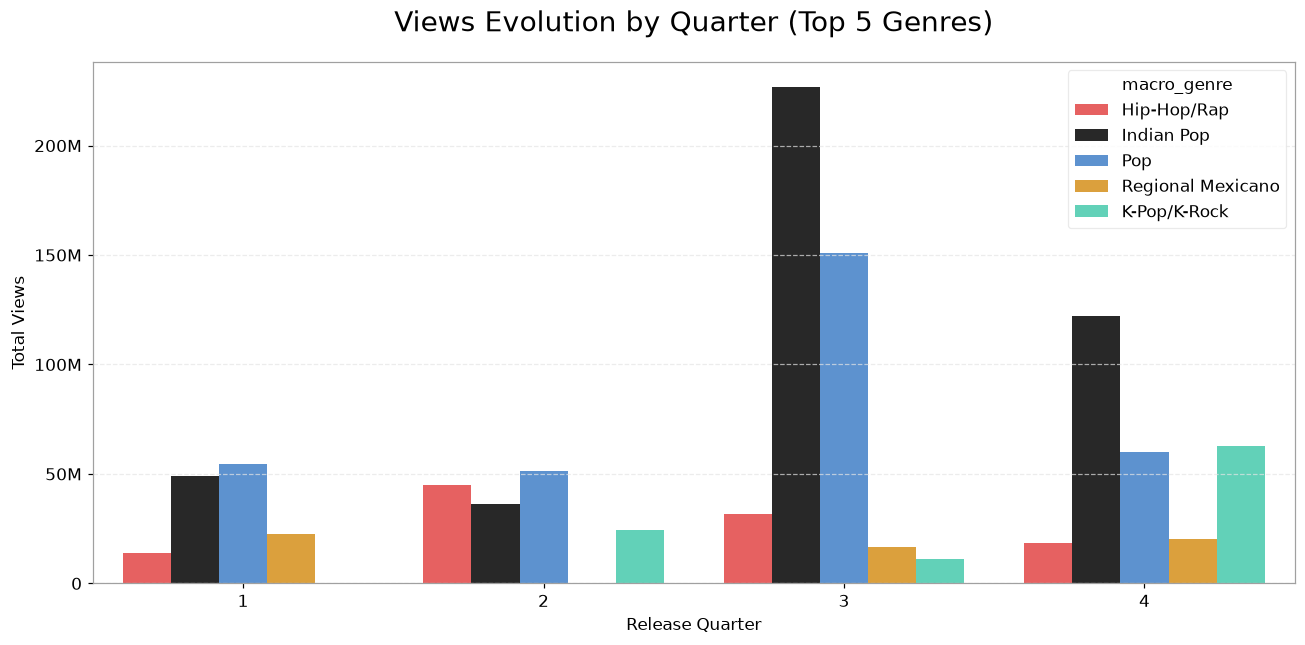

In [20]:
fig1, ax1 = plt.subplots(figsize=(12, 6))
fig1.patch.set_facecolor(YT_BG); ax1.set_facecolor(YT_BG)

# We use the CATEGORICAL_PALETTE to distinguish genres
sns.barplot(data=temporal_views, x='upload_quarter', y='views', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax1)

ax1.set_title('Views Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Total Views', fontsize=11, color=YT_TEXT)
ax1.yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax1, grid_axis='y')

legend1 = ax1.get_legend()
if legend1:
    legend1.get_frame().set_edgecolor(YT_GRID); legend1.get_frame().set_linewidth(0.8)
    for text in legend1.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

### 8.2. Engagement Evolution by Quarter

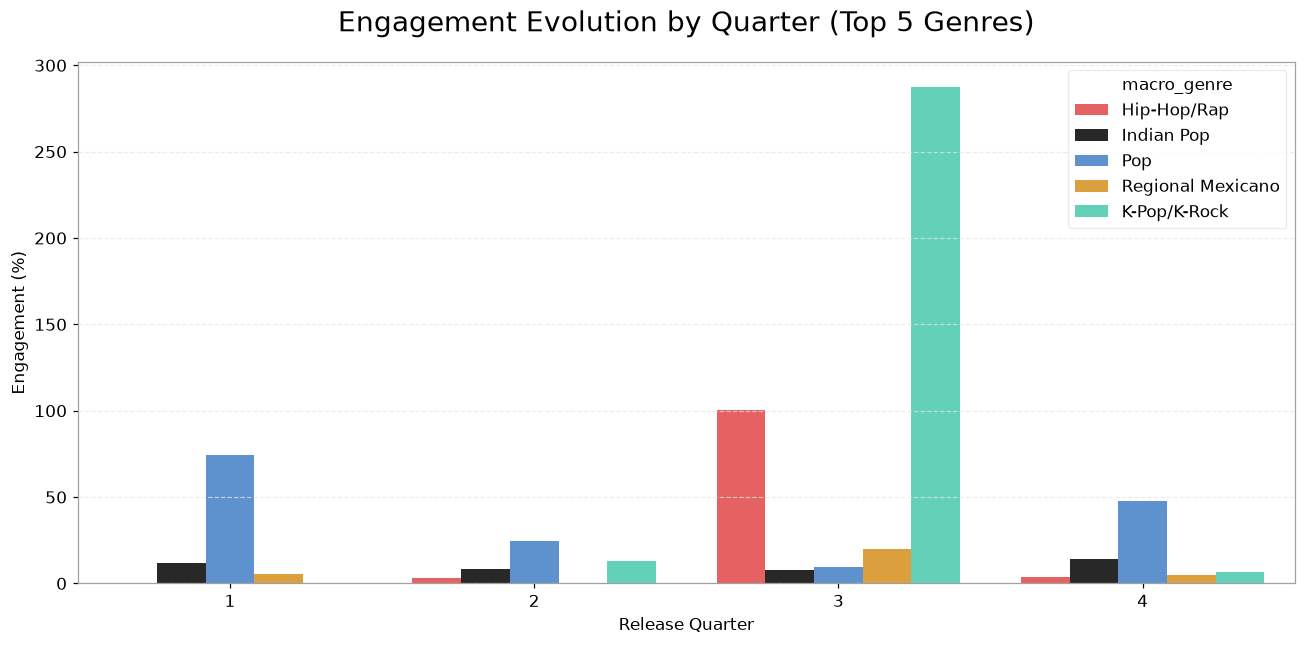

In [21]:
fig2, ax2 = plt.subplots(figsize=(12, 6))
fig2.patch.set_facecolor(YT_BG); ax2.set_facecolor(YT_BG)

sns.barplot(data=temporal_engagement, x='upload_quarter', y='engagement', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax2)

ax2.set_title('Engagement Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax2.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax2.set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

style_axes(ax2, grid_axis='y')

legend2 = ax2.get_legend()
if legend2:
    legend2.get_frame().set_edgecolor(YT_GRID); legend2.get_frame().set_linewidth(0.8)
    for text in legend2.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

### 8.3. Release Distribution by Quarter

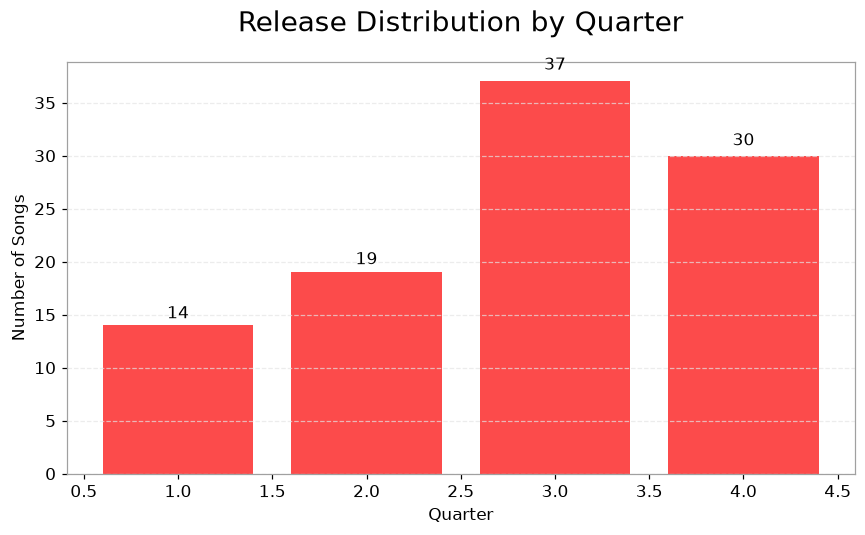

In [22]:
season_counts = df['upload_quarter'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.bar(season_counts.index, season_counts.values, color=YT_RED, edgecolor='none')

ax.set_xlabel('Quarter', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Release Distribution by Quarter', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='y')
add_bar_labels(ax, fmt='{:.0f}', horizontal=False)

plt.tight_layout(); plt.show()

## 9. Collaborations Analysis

,is_collaboration,count,avg_views,avg_engagement
0,Solo,81,"13,684,138",17.93%
1,Collaboration,19,"13,833,708",40.99%


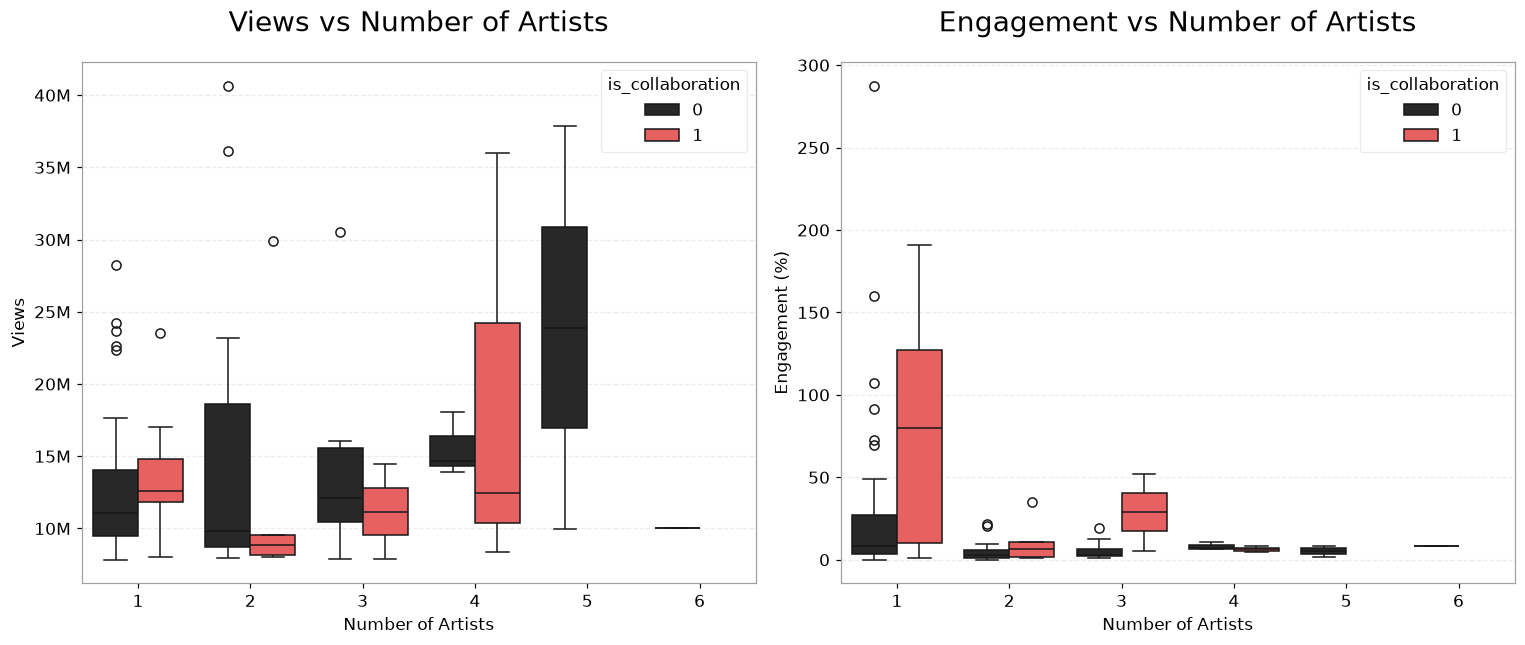

In [23]:
collab_stats = df.groupby('is_collaboration').agg(
    count=('track_name', 'count'),
    avg_views=('views', 'mean'),
    avg_engagement=('engagement', 'mean')
).reset_index()

collab_stats['is_collaboration'] = collab_stats['is_collaboration'].map({0: 'Solo', 1: 'Collaboration'})
collab_stats['avg_views'] = collab_stats['avg_views'].apply(lambda x: f'{x:,.0f}')
collab_stats['avg_engagement'] = collab_stats['avg_engagement'].round(2).astype(str) + '%'
display(collab_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(YT_BG)
axes[0].set_facecolor(YT_BG)
axes[1].set_facecolor(YT_BG)

sns.boxplot(
    data=df, x='artist_count', y='views', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=axes[0]
)
axes[0].set_title('Views vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
axes[0].set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
axes[0].set_ylabel('Views', fontsize=11, color=YT_TEXT)
axes[0].yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

sns.boxplot(
    data=df, x='artist_count', y='engagement', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=axes[1]
)
axes[1].set_title('Engagement vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
axes[1].set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
axes[1].set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

for ax in axes:
    style_axes(ax, grid_axis='y')
    legend = ax.get_legend()
    if legend:
        legend.get_frame().set_edgecolor(YT_GRID)
        legend.get_frame().set_linewidth(0.8)
        for text in legend.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

## 10. Executive Summary

In [24]:
stats = general_stats(df)
print(f"Songs: {stats['total_songs']}")
print(f"Countries: {stats['unique_countries']}")
print(f"Genres: {stats['unique_genres']}")
print(f"Total views: {format_number(stats['total_views'])}")
print(f"Total likes: {format_number(stats['total_likes'])}")
print(f"Avg engagement: {stats['avg_engagement']:.2f}%")

Songs: 100
Countries: 26
Genres: 17
Total views: 1.4B
Total likes: 253.8M
Avg engagement: 22.31%
